<a href="https://colab.research.google.com/github/Sathiyapramod/machine_learning/blob/main/linear_regression_study_hours.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub[pandas-datasets] scikit-learn matplotlib seaborn

import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "himanshunakrani/student-study-hours",
    "score.csv"
)

# Inspect dataset
print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())
print("\nData Info:")
print(df.info())

100%|██████████| 187/187 [00:00<00:00, 364kB/s]

Dataset Shape: (25, 2)

First 5 records:
   Hours  Scores
0    2.5      21
1    5.1      47
2    3.2      27
3    8.5      75
4    3.5      30

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   25 non-null     float64
 1   Scores  25 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 532.0 bytes
None


# Exploratory Data Analysis (EDA)

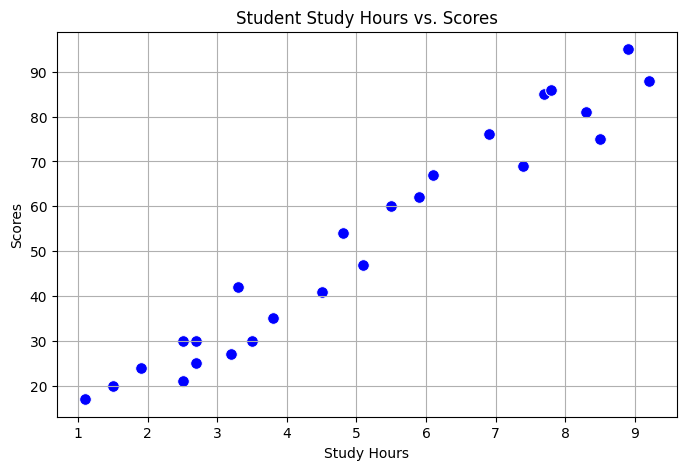

In [5]:
# Scatter plot of Years of Experience vs Salary
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Hours', y='Scores', color='blue', s=70)
plt.title('Student Study Hours vs. Scores')
plt.xlabel('Study Hours')
plt.ylabel('Scores')
plt.grid(True)
plt.show()

# Target Split & Train-Test Split

In [6]:
# Separate Features (X) and Target (y)
# Reshape X to 2D array as required by scikit-learn

X = df[['Hours']]
y = df['Scores']

# Split data: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 20, Testing samples: 5


# Model Training

In [8]:
# Initialize and fit Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Print parameters
print(f"Intercept (β0): {model.intercept_:.2f}")
print(f"Slope (β1): {model.coef_[0]:.2f}")
print(f"\nModel Equation: Score = {model.intercept_:.2f} + ({model.coef_[0]:.2f} * StudyHours)")

Intercept (β0): 2.83
Slope (β1): 9.68

Model Equation: Score = 2.83 + (9.68 * StudyHours)


Mean Squared Error (MSE): 18.94
Root Mean Squared Error (RMSE): 4.35
R-squared (R²): 0.9678


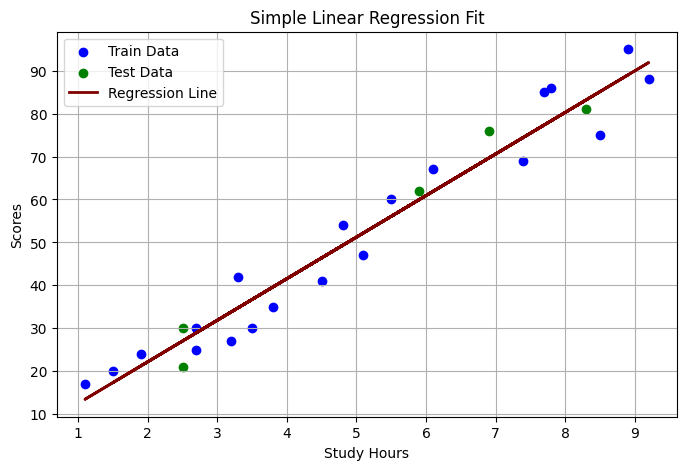

In [9]:
# Make predictions on test set
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")

# Plot Regression Line
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', label='Train Data')
plt.scatter(X_test, y_test, color='green', label='Test Data')
plt.plot(X, model.predict(X), color='maroon', linewidth=2, label='Regression Line')
plt.title('Simple Linear Regression Fit')
plt.xlabel('Study Hours')
plt.ylabel('Scores')
plt.legend()
plt.grid(True)
plt.show()